# Credit Default Classification

## Background and Problem

Predicting credit card defaults is essential for credit systems to remain solvent, functionable, and profitable by ensuring clients are only issued credit if they are generally able to pay it and ensuring clients receive interest rates proportional to the risk of lending to them. A wide range of factors can be considered in determining whether someone will default and what the probability is.

In this analysis we look at the UCI Credit Default dataset, containing around 30,000 observations of real clients in Taiwan around 2009. We aim to use classification methods to answer the question: Which customers default, and which classifier catches them best?

We will prepare the data, generate potentially useful features and drop potentially obstructive ones, and try three classification methods covered in CMSE 202: logistic regression, a support vector machine, and the perceptron. Using training data and a testing set, we will measure the comparitive accuracy, sensitivity, and specificity of these methods to compare and find which performs best and what is the best choice overall given other factors like interpretability.

## Data Description

## Preparation and Feature Generation

First we load in the necessary packages for our analysis:

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression

Then we load in the credit default dataset:

In [11]:
default = pd.read_csv('default.csv')
default.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


We get rid of the extra column labels on the top and instead use the more descriptive first row as column labels. We also ensure all columns are read as numeric for now:

In [13]:
default.columns = default.iloc[0]
default = default[1:]
default.reset_index(drop = True, inplace = True)
default = default.apply(pd.to_numeric, errors = 'coerce')

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


ID will not provide us any useful information in predicting defaults, so we drop it:

In [14]:
default = default.drop(columns = ['ID'])

We check for NaN's and see that we have none:

In [15]:
print(default.isna().sum().sum())

0


Now we will create some potentially useful features from the data that can generalize some columns and highlight potentially relevant behavior from others:

- Late months: How many months was the client late on their payment?
- Average bill: What was the average of bill amounts?
- Average utilization: Average bill over the users' credit limit.
- Max utilization: Maximum utilization over the time period.
- Average payment: What was the average of the payment amounts?
- Payment ratio: Average payment over average bill.
- Max delay: The most severe payment delay the customer had in the last 6 months.
- Recent late: Number of months with payment delays in the past three months.

In [16]:
default['LATE_MONTHS'] = (default[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']] > 0).sum(axis = 1)
default['AVG_BILL'] = (default['BILL_AMT1'] + default['BILL_AMT2'] + default['BILL_AMT3'] + default['BILL_AMT4'] + default['BILL_AMT5'] + default['BILL_AMT6']) / 6
default['AVG_UTILIZATION'] = default['AVG_BILL'] / default['LIMIT_BAL']
default['AVG_PAYMENT'] = (default['PAY_AMT1'] + default['PAY_AMT2'] + default['PAY_AMT3'] + default['PAY_AMT4'] + default['PAY_AMT5'] + default['PAY_AMT6']) / 6
default['MAX_DELAY'] = default[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].max(axis = 1)
default['RECENT_LATE'] = (default[['PAY_0', 'PAY_2', 'PAY_3']] > 0).sum(axis = 1)
default['PAYMENT_RATIO'] = default['AVG_PAYMENT'] / default['AVG_BILL']
default['MAX_UTILIZATION'] = default[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].max(axis = 1) / default['LIMIT_BAL'].replace(0, np.nan)

We look once more for any NaN's created by our feature transformations:

In [17]:
print('NaN:', default.isna().sum() + np.isposinf(default).sum() + np.isneginf(default).sum())

NaN: 0
LIMIT_BAL                       0
SEX                             0
EDUCATION                       0
MARRIAGE                        0
AGE                             0
PAY_0                           0
PAY_2                           0
PAY_3                           0
PAY_4                           0
PAY_5                           0
PAY_6                           0
BILL_AMT1                       0
BILL_AMT2                       0
BILL_AMT3                       0
BILL_AMT4                       0
BILL_AMT5                       0
BILL_AMT6                       0
PAY_AMT1                        0
PAY_AMT2                        0
PAY_AMT3                        0
PAY_AMT4                        0
PAY_AMT5                        0
PAY_AMT6                        0
default payment next month      0
LATE_MONTHS                     0
AVG_BILL                        0
AVG_UTILIZATION                 0
AVG_PAYMENT                     0
MAX_DELAY                       0
RECENT_

We can see that adding the payment ratio caused 870 NaN's/inf's to be introduced, likely because the client's average bill in these cases was 0. Because the concept of credit default is more difficult to apply to customers who have no credit usage, and because these cases make up a relatively small proportion of the data, we are going to choose to drop them:

In [32]:
default = default.replace([np.inf, -np.inf], np.nan)
default = default.dropna()

In order to avoid severe multicollinearity which could diminish the accuracy of regression coefficients, and to simplify the model, we will look at the correlations among the numeric features and see which ones are excessively correlated:

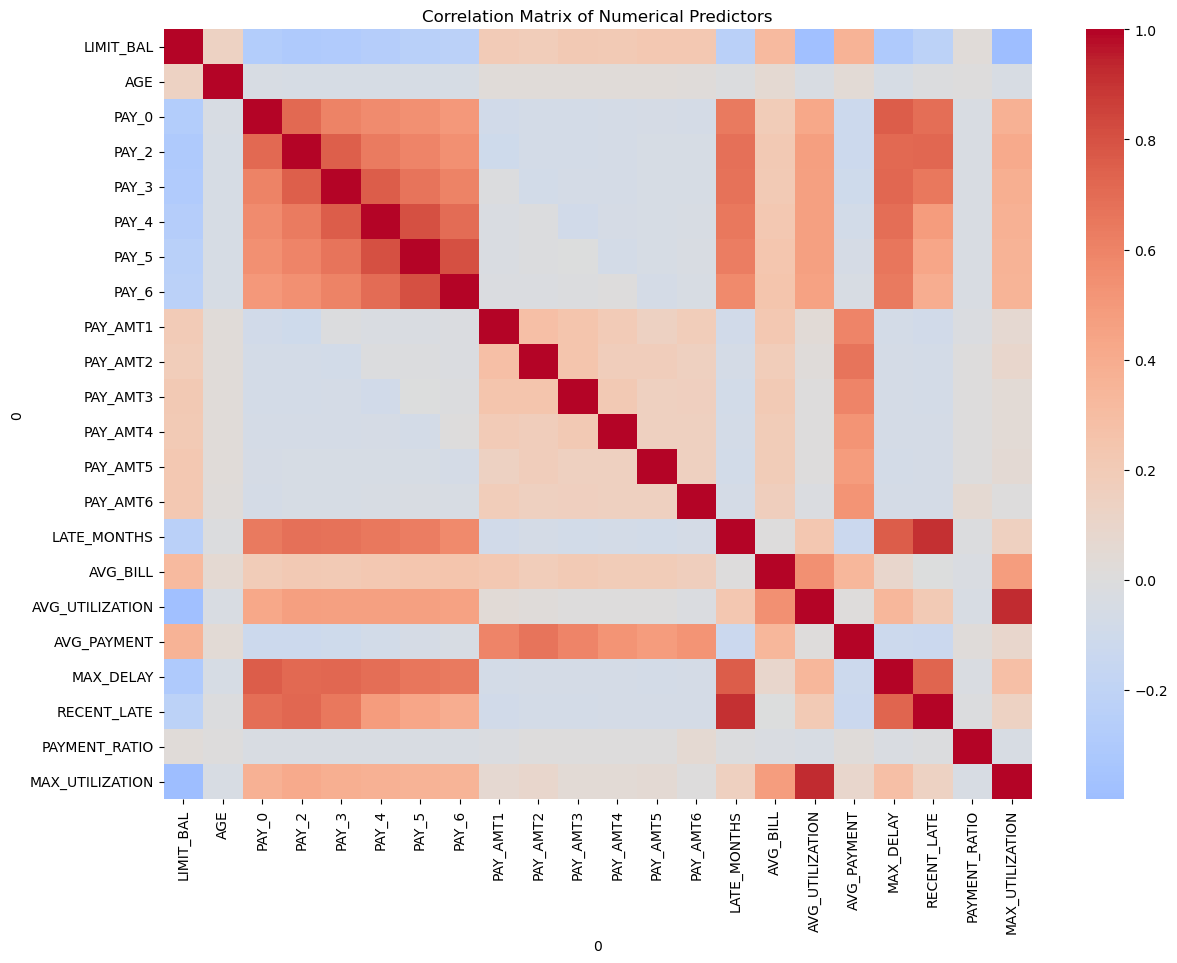

In [33]:
numerical = default.drop(columns = ['SEX', 'EDUCATION', 'MARRIAGE', 'default payment next month'])
plt.figure(figsize = (14, 10))
sns.heatmap(numerical.corr(), cmap = 'coolwarm', center = 0)
plt.title('Correlations of Numerical Predictors')
plt.show()

We see there is almost a perfect correlation among the BILL_AMT features and between them and AVG_BILL, so since AVG_BILL contains the information what we want out of these values, we choose to keep it and drop the indiviual BILL_AMT's.

In [34]:
dropcols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
default = default.drop(columns = dropcols)

KeyError: "['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6'] not found in axis"

Next, we notice that there are some values in EDUCATION and MARRIAGE that are outside the ones defined in the data dictionary. We fix this by categorizing any numbers besides the mentioned ones into the 'others' category:

In [27]:
default.loc[~default['EDUCATION'].isin([1, 2, 3, 4]), 'EDUCATION'] = 4
default.loc[~default['MARRIAGE'].isin([1, 2, 3]), 'MARRIAGE'] = 3

Before we train our models, we must separate the data into the predictors and the response:

In [35]:
X = default.drop(columns = ['default payment next month'])
y = default['default payment next month']

We split our data into a training set with 80% of observations and a testing set with 20% of observations:

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)

We create dummy variables for the categorical predictors so they can be used in regression algorithms:

In [19]:
X_train = pd.get_dummies(X_train, columns = ['SEX', 'EDUCATION', 'MARRIAGE'], dtype = int)
X_test = pd.get_dummies(X_test, columns = ['SEX', 'EDUCATION', 'MARRIAGE'], dtype = int)
X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)

And finally we standardize the predictors so that variables of a larger scale do not dominate distance or other regression calculations:

In [20]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns = X_test.columns, index = X_test.index)

## Model 1: Logistic Regression

## Model 2: Support Vector Machine

## Model 3: Perceptron Classifier

In [40]:
from sklearn.linear_model import Perceptron

max_iter = 40        #How many times over the model will be updated 
eta0 = 0.4           #learning rate

ppn = Perceptron(max_iter = max_iter,              #Creates call to perceptron
                eta0 = eta0,
                random_state = 0)

ppn.fit(X_train, y_train)    #Uses training set on model

y_pred_percept = ppn.predict(X_test)     #creates predicted values for test data 

In [44]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred_percept)    #compares actual vs predicted 

0.7030552694816341

In [39]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred_percept)

array([[3890,  670],
       [1060,  206]])

## Comparison and Evaluation

## Conclusion

## References

Model 3: 
* https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html
* https://www.youtube.com/watch?v=oLane_Vh3CU
* https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html